# Практическая работа: Реализация линейной регрессии с нуля

**Цель работы:** Написать собственный класс линейной регрессии с поддержкой аналитического решения (МНК) и градиентного спуска, а также реализовать функции для оценки качества модели.

In [13]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

plt.style.use('seaborn-v0_8-darkgrid')
plt.rcParams['figure.figsize'] = (10, 6)

## 1. Реализация класса линейной регрессии
Класс `MyLinearRegression` поддерживает оба метода оптимизации. Метрики $MSE$ и коэффициент детерминации $R^2$ реализованы как методы класса.

In [14]:
class MyLinearRegression:
    def __init__(self, method='analytical', learning_rate=0.01, n_iters=1000):
        self.method = method
        self.learning_rate = learning_rate
        self.n_iters = n_iters
        self.weights = None
        self.loss_history = []
        
    def _add_intercept(self, X):
        intercept = np.ones((X.shape[0], 1))
        return np.concatenate((intercept, X), axis=1)
        
    def fit(self, X, y):
        X_ext = self._add_intercept(X)
        n_samples, n_features = X_ext.shape
        
        if self.method == 'analytical':
            # w = (X^T * X)^(-1) * X^T * y
            X_T = X_ext.T
            self.weights = np.linalg.inv(X_T @ X_ext) @ X_T @ y
            
        elif self.method == 'gd':
            self.weights = np.zeros(n_features)
            
            for i in range(self.n_iters):
                predictions = X_ext @ self.weights
                errors = predictions - y
                
                gradient = (2 / n_samples) * (X_ext.T @ errors)
                
                self.weights -= self.learning_rate * gradient
                
                mse = np.mean(errors ** 2)
                self.loss_history.append(mse)
        else:
            raise ValueError("Unknown method. Choose 'analytical' или 'gd'.")
            
    def predict(self, X):
        X_ext = self._add_intercept(X)
        return X_ext @ self.weights
    
    @staticmethod
    def mse(y_true, y_pred):
        return np.mean((y_true - y_pred) ** 2)
    
    @staticmethod
    def r2_score(y_true, y_pred):
        ss_res = np.sum((y_true - y_pred) ** 2)
        ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
        return 1 - (ss_res / ss_tot)

## 2. Генерация синтетических данных
Создадим данные, описываемые линейной зависимостью $y = 3x_1 - 2x_2 + 5$, и добавим нормальный шум $\varepsilon \sim \mathcal{N}(0, 2^2)$.

In [15]:
N_samples = 200
X = 10 * np.random.rand(N_samples, 2)

true_weights = np.array([5, 3, -2])

noise = np.random.normal(0, 2, size=N_samples)
y = 5 + 3 * X[:, 0] - 2 * X[:, 1] + noise

split_idx = int(N_samples * 0.8)
X_train, X_test = X[:split_idx], X[split_idx:]
y_train, y_test = y[:split_idx], y[split_idx:]

print(f"Обучающая выборка: X_train {X_train.shape}, y_train {y_train.shape}")
print(f"Тестовая выборка: X_test {X_test.shape}, y_test {y_test.shape}")

Обучающая выборка: X_train (160, 2), y_train (160,)
Тестовая выборка: X_test (40, 2), y_test (40,)


## 3. Обучение моделей и оценка качества
Сравним работу аналитического решения (МНК) и алгоритма градиентного спуска по метрикам MSE и $R^2$.

Аналитическое решение (МНК)
Веса: [ 5.22055102  3.01717221 -2.06385634]
MSE: 4.7410 | R^2: 0.9435

Градиентный спуск
Веса: [ 4.9688836   3.03813056 -2.04146239]
MSE: 4.7318 | R^2: 0.9436


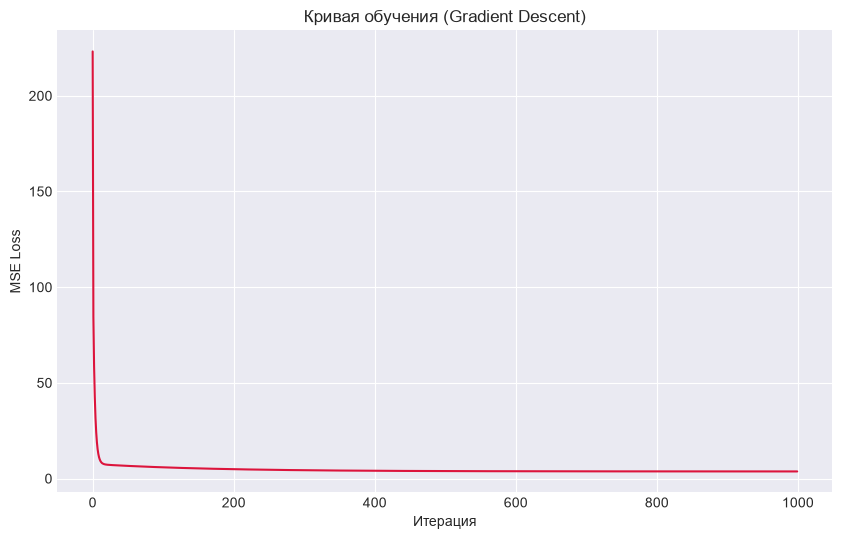

In [16]:
model_analytical = MyLinearRegression(method='analytical')
model_analytical.fit(X_train, y_train)
y_pred_analytical = model_analytical.predict(X_test)

mse_a = MyLinearRegression.mse(y_test, y_pred_analytical)
r2_a = MyLinearRegression.r2_score(y_test, y_pred_analytical)

model_gd = MyLinearRegression(method='gd', learning_rate=0.01, n_iters=1000)
model_gd.fit(X_train, y_train)
y_pred_gd = model_gd.predict(X_test)

mse_gd = MyLinearRegression.mse(y_test, y_pred_gd)
r2_gd = MyLinearRegression.r2_score(y_test, y_pred_gd)

print("Аналитическое решение (МНК)")
print(f"Веса: {model_analytical.weights}")
print(f"MSE: {mse_a:.4f} | R^2: {r2_a:.4f}\n")

print("Градиентный спуск")
print(f"Веса: {model_gd.weights}")
print(f"MSE: {mse_gd:.4f} | R^2: {r2_gd:.4f}")

plt.plot(model_gd.loss_history, color='crimson')
plt.title('Кривая обучения (Gradient Descent)')
plt.xlabel('Итерация')
plt.ylabel('MSE Loss')
plt.show()